# 05.03 — Categorical counts and subgroup availability

**Stage:** `data_inspection` · **Notebook 3 of 3**  
**Purpose:** inspect the **observed composition of the final analytical cohort** using the five non-HRV categorical factors, with interpretable marginal counts and pairwise cross-tabulations.  
**Input:** `outputs/dataset_final.csv` — current preprocessing release **402 records**.  
**No HRV measurements, statistical tests, predictive models, arbitrary exclusions, or 3+ factor intersections.**

This completes the three-part inspection stage:

1. `05_01_hrv_inspection.ipynb` — descriptive HRV measurements.
2. `05_02_non_hrv_inspection.ipynb` — descriptive continuous non-HRV measurements.
3. `05_03_category_counts.ipynb` — **categorical frequencies and two-factor sample availability** (this notebook).

**Important distinction:** two-way tables here only document *how many records are available in each observed combination*. They do not compare HRV values, test differences between groups, or establish which groups should be modeled. Zeros and small cell sizes are reported faithfully; no categories are merged or discarded.

## 1. Configuration, input, and categorical-data validation

Only the final cohort is used. Values are checked against the categories produced by preprocessing; **no categories are reconstructed in the output, no records are filtered, and no source measurements are changed**. A mismatch raises an explicit error and should be resolved upstream.

The five factors are: age group, sex, BMI category, systolic BP category, and diastolic BP category. `bmi_reference` is recorded as **classification metadata**, not as a sixth independent explanatory factor.

In [1]:
from pathlib import Path
from itertools import combinations
from hashlib import sha256
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

EXPECTED_N = 402  # Documentation reference, NOT a sample-size filter.
INPUT_FILE_OVERRIDE = None  # Example: Path('/absolute/path/dataset_final.csv')
SAVE_DPI = 160
SHOW_MULTIPANELS_IN_NOTEBOOK = True
REPLACE_PREVIOUS_GENERATED_FIGURES = True  # Restricts cleanup to this notebook's old manifest.

SOURCE_COLUMN = 'source_excel_row'
FACTOR_LEVELS = {
    'age_group': ['60-69', '70-79', '80+'],
    'sex_category': ['Female', 'Male'],
    'bmi_category': ['Underweight', 'Normal', 'Overweight', 'Obesity'],
    'sbp_category': ['<140 mmHg', '>=140 mmHg'],
    'dbp_category': ['<90 mmHg', '>=90 mmHg'],
}
FACTOR_LABELS = {
    'age_group': 'Age group',
    'sex_category': 'Sex',
    'bmi_category': 'BMI category',
    'sbp_category': 'SBP category',
    'dbp_category': 'DBP category',
}
PAIR_SECTIONS = {
    'demographic_anthropometric': [
        ('age_group', 'sex_category'),
        ('age_group', 'bmi_category'),
        ('sex_category', 'bmi_category'),
    ],
    'blood_pressure_and_bmi': [
        ('sbp_category', 'dbp_category'),
        ('bmi_category', 'sbp_category'),
        ('bmi_category', 'dbp_category'),
    ],
    'demographics_and_blood_pressure': [
        ('age_group', 'sbp_category'),
        ('age_group', 'dbp_category'),
        ('sex_category', 'sbp_category'),
        ('sex_category', 'dbp_category'),
    ],
}
ALL_PAIRS = [pair for pair_list in PAIR_SECTIONS.values() for pair in pair_list]
assert len(ALL_PAIRS) == len(set(ALL_PAIRS)) == 10
assert {frozenset(pair) for pair in ALL_PAIRS} == {frozenset(pair) for pair in combinations(FACTOR_LEVELS, 2)}


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'outputs' / 'dataset_final.csv').is_file():
            return candidate
    raise FileNotFoundError(
        'Cannot locate outputs/dataset_final.csv from the working directory. '
        'Set INPUT_FILE_OVERRIDE or run from the project tree.'
    )

if INPUT_FILE_OVERRIDE is None:
    PROJECT_ROOT = find_project_root(Path.cwd().resolve())
    INPUT_FILE = PROJECT_ROOT / 'outputs' / 'dataset_final.csv'
else:
    INPUT_FILE = Path(INPUT_FILE_OVERRIDE).expanduser().resolve()
    if not INPUT_FILE.is_file():
        raise FileNotFoundError(f'Missing input file: {INPUT_FILE}')
    PROJECT_ROOT = INPUT_FILE.parent.parent

OUTPUT_DIR = PROJECT_ROOT / 'eda_results' / 'data_inspection' / '05_03_category_counts'
TABLES_DIR = OUTPUT_DIR / 'tables'
MULTIPANEL_DIR = OUTPUT_DIR / 'figures' / 'multipanels'
for directory in (TABLES_DIR, MULTIPANEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

source_df = pd.read_csv(INPUT_FILE)
required = [
    SOURCE_COLUMN, 'age', 'sex', 'imc', 'bp_systolic', 'bp_diastolic',
    'bmi_reference', *FACTOR_LEVELS,
]
missing_columns = [c for c in required if c not in source_df.columns]
if missing_columns:
    raise ValueError(f'Input is missing required columns: {missing_columns}')
if source_df.empty:
    raise ValueError('The analytical cohort is empty.')
if source_df[SOURCE_COLUMN].isna().any() or source_df[SOURCE_COLUMN].duplicated().any():
    raise ValueError('source_excel_row must be unique and nonmissing.')
for column in ('age', 'sex', 'imc', 'bp_systolic', 'bp_diastolic'):
    if not pd.api.types.is_numeric_dtype(source_df[column]):
        raise TypeError(f'Expected numeric source column: {column}')
    if not np.isfinite(source_df[column].dropna().to_numpy(dtype=float)).all():
        raise ValueError(f'Nonfinite numerical observations in {column}.')
for column, levels in FACTOR_LEVELS.items():
    unexpected = sorted(set(source_df[column].dropna().unique()) - set(levels))
    if unexpected:
        raise ValueError(f'{column}: unexpected categories {unexpected}; check preprocessing output.')

N_RECORDS = len(source_df)
if N_RECORDS != EXPECTED_N:
    print(f'NOTE: Current cohort has {N_RECORDS} records, documented release has {EXPECTED_N}; no rows removed.')
else:
    print(f'Analytical cohort verified: {N_RECORDS} records.')

# Validate the stored labels against the continuous inputs. These are checks only.
if (source_df['age'].dropna() < 60).any():
    raise ValueError('The final cohort contains age <60; check upstream eligibility decisions.')

expected_age = pd.Series(np.select(
    [source_df['age'] < 70, source_df['age'] < 80, source_df['age'] >= 80],
    ['60-69', '70-79', '80+'], default=None,
), index=source_df.index, dtype='object').where(source_df['age'].notna())
expected_sex = source_df['sex'].map({1: 'Female', 2: 'Male'})
expected_sbp = pd.Series(
    np.where(source_df['bp_systolic'] < 140, '<140 mmHg', '>=140 mmHg'), index=source_df.index,
).where(source_df['bp_systolic'].notna() & (source_df['bp_systolic'] > 0))
expected_dbp = pd.Series(
    np.where(source_df['bp_diastolic'] < 90, '<90 mmHg', '>=90 mmHg'), index=source_df.index,
).where(source_df['bp_diastolic'].notna() & (source_df['bp_diastolic'] > 0))
expected_bmi = pd.cut(
    source_df['imc'], bins=[-np.inf, 23, 28, 32, np.inf],
    right=False, labels=FACTOR_LEVELS['bmi_category'],
).astype('object')
expected_labels = {
    'age_group': expected_age, 'sex_category': expected_sex,
    'bmi_category': expected_bmi, 'sbp_category': expected_sbp,
    'dbp_category': expected_dbp,
}
validation_records = []
for column, expected in expected_labels.items():
    observed = source_df[column].astype('object')
    mismatch = (~(observed.eq(expected) | (observed.isna() & expected.isna()))).fillna(True)
    validation_records.append({
        'factor': column, 'n_records': N_RECORDS,
        'n_mismatch': int(mismatch.sum()),
        'source_excel_rows_mismatched': ';'.join(source_df.loc[mismatch, SOURCE_COLUMN].astype(str)),
        'validation': 'observed_category_matches_recorded_continuous_source',
    })
    if mismatch.any():
        raise ValueError(
            f'Category/source mismatch in {column}; source Excel rows: '
            f'{source_df.loc[mismatch, SOURCE_COLUMN].tolist()[:15]}'
        )

if not source_df['bmi_reference'].eq('MINSAL older person (>=60)').all():
    raise ValueError('Unexpected BMI reference in final older-adult cohort.')

validation = pd.DataFrame(validation_records)
validation.to_csv(TABLES_DIR / 'categorical_source_consistency_checks.csv', index=False)

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': SAVE_DPI,
    'axes.titlesize': 11, 'axes.titleweight': 'semibold',
    'axes.labelsize': 9.5, 'font.size': 9.5,
})

# Only old PNG files listed in this notebook's previous figure manifest may be removed.
old_manifest_path = TABLES_DIR / 'figure_manifest.csv'
if REPLACE_PREVIOUS_GENERATED_FIGURES and old_manifest_path.is_file():
    old_manifest = pd.read_csv(old_manifest_path)
    for relative in old_manifest.get('figure', pd.Series(dtype=str)).dropna():
        old_file = (OUTPUT_DIR / str(relative)).resolve()
        if old_file.is_relative_to(MULTIPANEL_DIR.resolve()) and old_file.is_file() and old_file.suffix == '.png':
            old_file.unlink()

INPUT_SHA256 = sha256(INPUT_FILE.read_bytes()).hexdigest()
figure_records = []


def save_figure(fig, filename, kind, description):
    path = MULTIPANEL_DIR / filename
    fig.savefig(path, dpi=SAVE_DPI, bbox_inches='tight', facecolor='white')
    figure_records.append({
        'figure': str(path.relative_to(OUTPUT_DIR)),
        'kind': kind,
        'description': description,
    })
    plt.close(fig)
    return path


def show_panel(path, width=1100):
    if SHOW_MULTIPANELS_IN_NOTEBOOK:
        display(Image(filename=str(path), width=width))

print('Input:', INPUT_FILE)
print('Output:', OUTPUT_DIR)
print('All classification/source-value checks passed. No source data changed.')

Analytical cohort verified: 402 records.
Input: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/outputs/dataset_final.csv
Output: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_03_category_counts
All classification/source-value checks passed. No source data changed.


## 2. Marginal category counts and proportions

For each of the **five** factors, report every documented level (including possible zero-count levels), its record count, percentage **among nonmissing labels** and percentage **of the full input cohort**. Missing values would be reported separately and never silently omitted from the accounting. The present final cohort is complete for these factors.

In [2]:
marginal_rows = []
for factor, levels in FACTOR_LEVELS.items():
    counts = source_df[factor].value_counts(dropna=False)
    n_missing = int(source_df[factor].isna().sum())
    n_valid = N_RECORDS - n_missing
    for level in levels:
        n = int(counts.get(level, 0))
        marginal_rows.append({
            'factor': factor, 'factor_label': FACTOR_LABELS[factor],
            'category': level, 'n': n,
            'pct_valid': 100 * n / n_valid if n_valid else np.nan,
            'pct_of_all_records': 100 * n / N_RECORDS,
            'n_valid_factor': n_valid, 'n_missing_factor': n_missing,
            'n_total_records': N_RECORDS,
        })
    marginal_rows.append({
        'factor': factor, 'factor_label': FACTOR_LABELS[factor],
        'category': '(missing)', 'n': n_missing,
        'pct_valid': np.nan,
        'pct_of_all_records': 100 * n_missing / N_RECORDS,
        'n_valid_factor': n_valid, 'n_missing_factor': n_missing,
        'n_total_records': N_RECORDS,
    })

marginal = pd.DataFrame(marginal_rows)
for factor in FACTOR_LEVELS:
    block = marginal.loc[marginal.factor == factor]
    assert int(block['n'].sum()) == N_RECORDS, factor
    assert int(block.loc[block.category != '(missing)', 'n'].sum()) == int(block['n_valid_factor'].iloc[0])

marginal.to_csv(TABLES_DIR / 'categorical_marginal_counts.csv', index=False)
reference_counts = (source_df['bmi_reference'].value_counts(dropna=False)
                    .rename_axis('bmi_reference').reset_index(name='n'))
reference_counts['pct_of_all_records'] = 100 * reference_counts['n'] / N_RECORDS
reference_counts.to_csv(TABLES_DIR / 'bmi_reference_metadata_counts.csv', index=False)

display(marginal[marginal.category != '(missing)'][
    ['factor_label', 'category', 'n', 'pct_valid']
].round(1))
print('BMI reference is counted separately as metadata, not used as an explanatory factor.')

,factor_label,category,n,pct_valid
0,Age group,60-69,184,45.8
1,Age group,70-79,190,47.3
2,Age group,80+,28,7.0
4,Sex,Female,294,73.1
5,Sex,Male,108,26.9
7,BMI category,Underweight,17,4.2
8,BMI category,Normal,118,29.4
9,BMI category,Overweight,117,29.1
10,BMI category,Obesity,150,37.3
12,SBP category,<140 mmHg,298,74.1


BMI reference is counted separately as metadata, not used as an explanatory factor.


## 3. Multipanel of marginal category frequencies

Each panel displays absolute `n` and percentage of the **nonmissing records for that specific factor**. The sixth panel highlights the smallest category in each factor; missing-category totals remain in the data tables. These are within-factor descriptions, not HRV comparisons.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


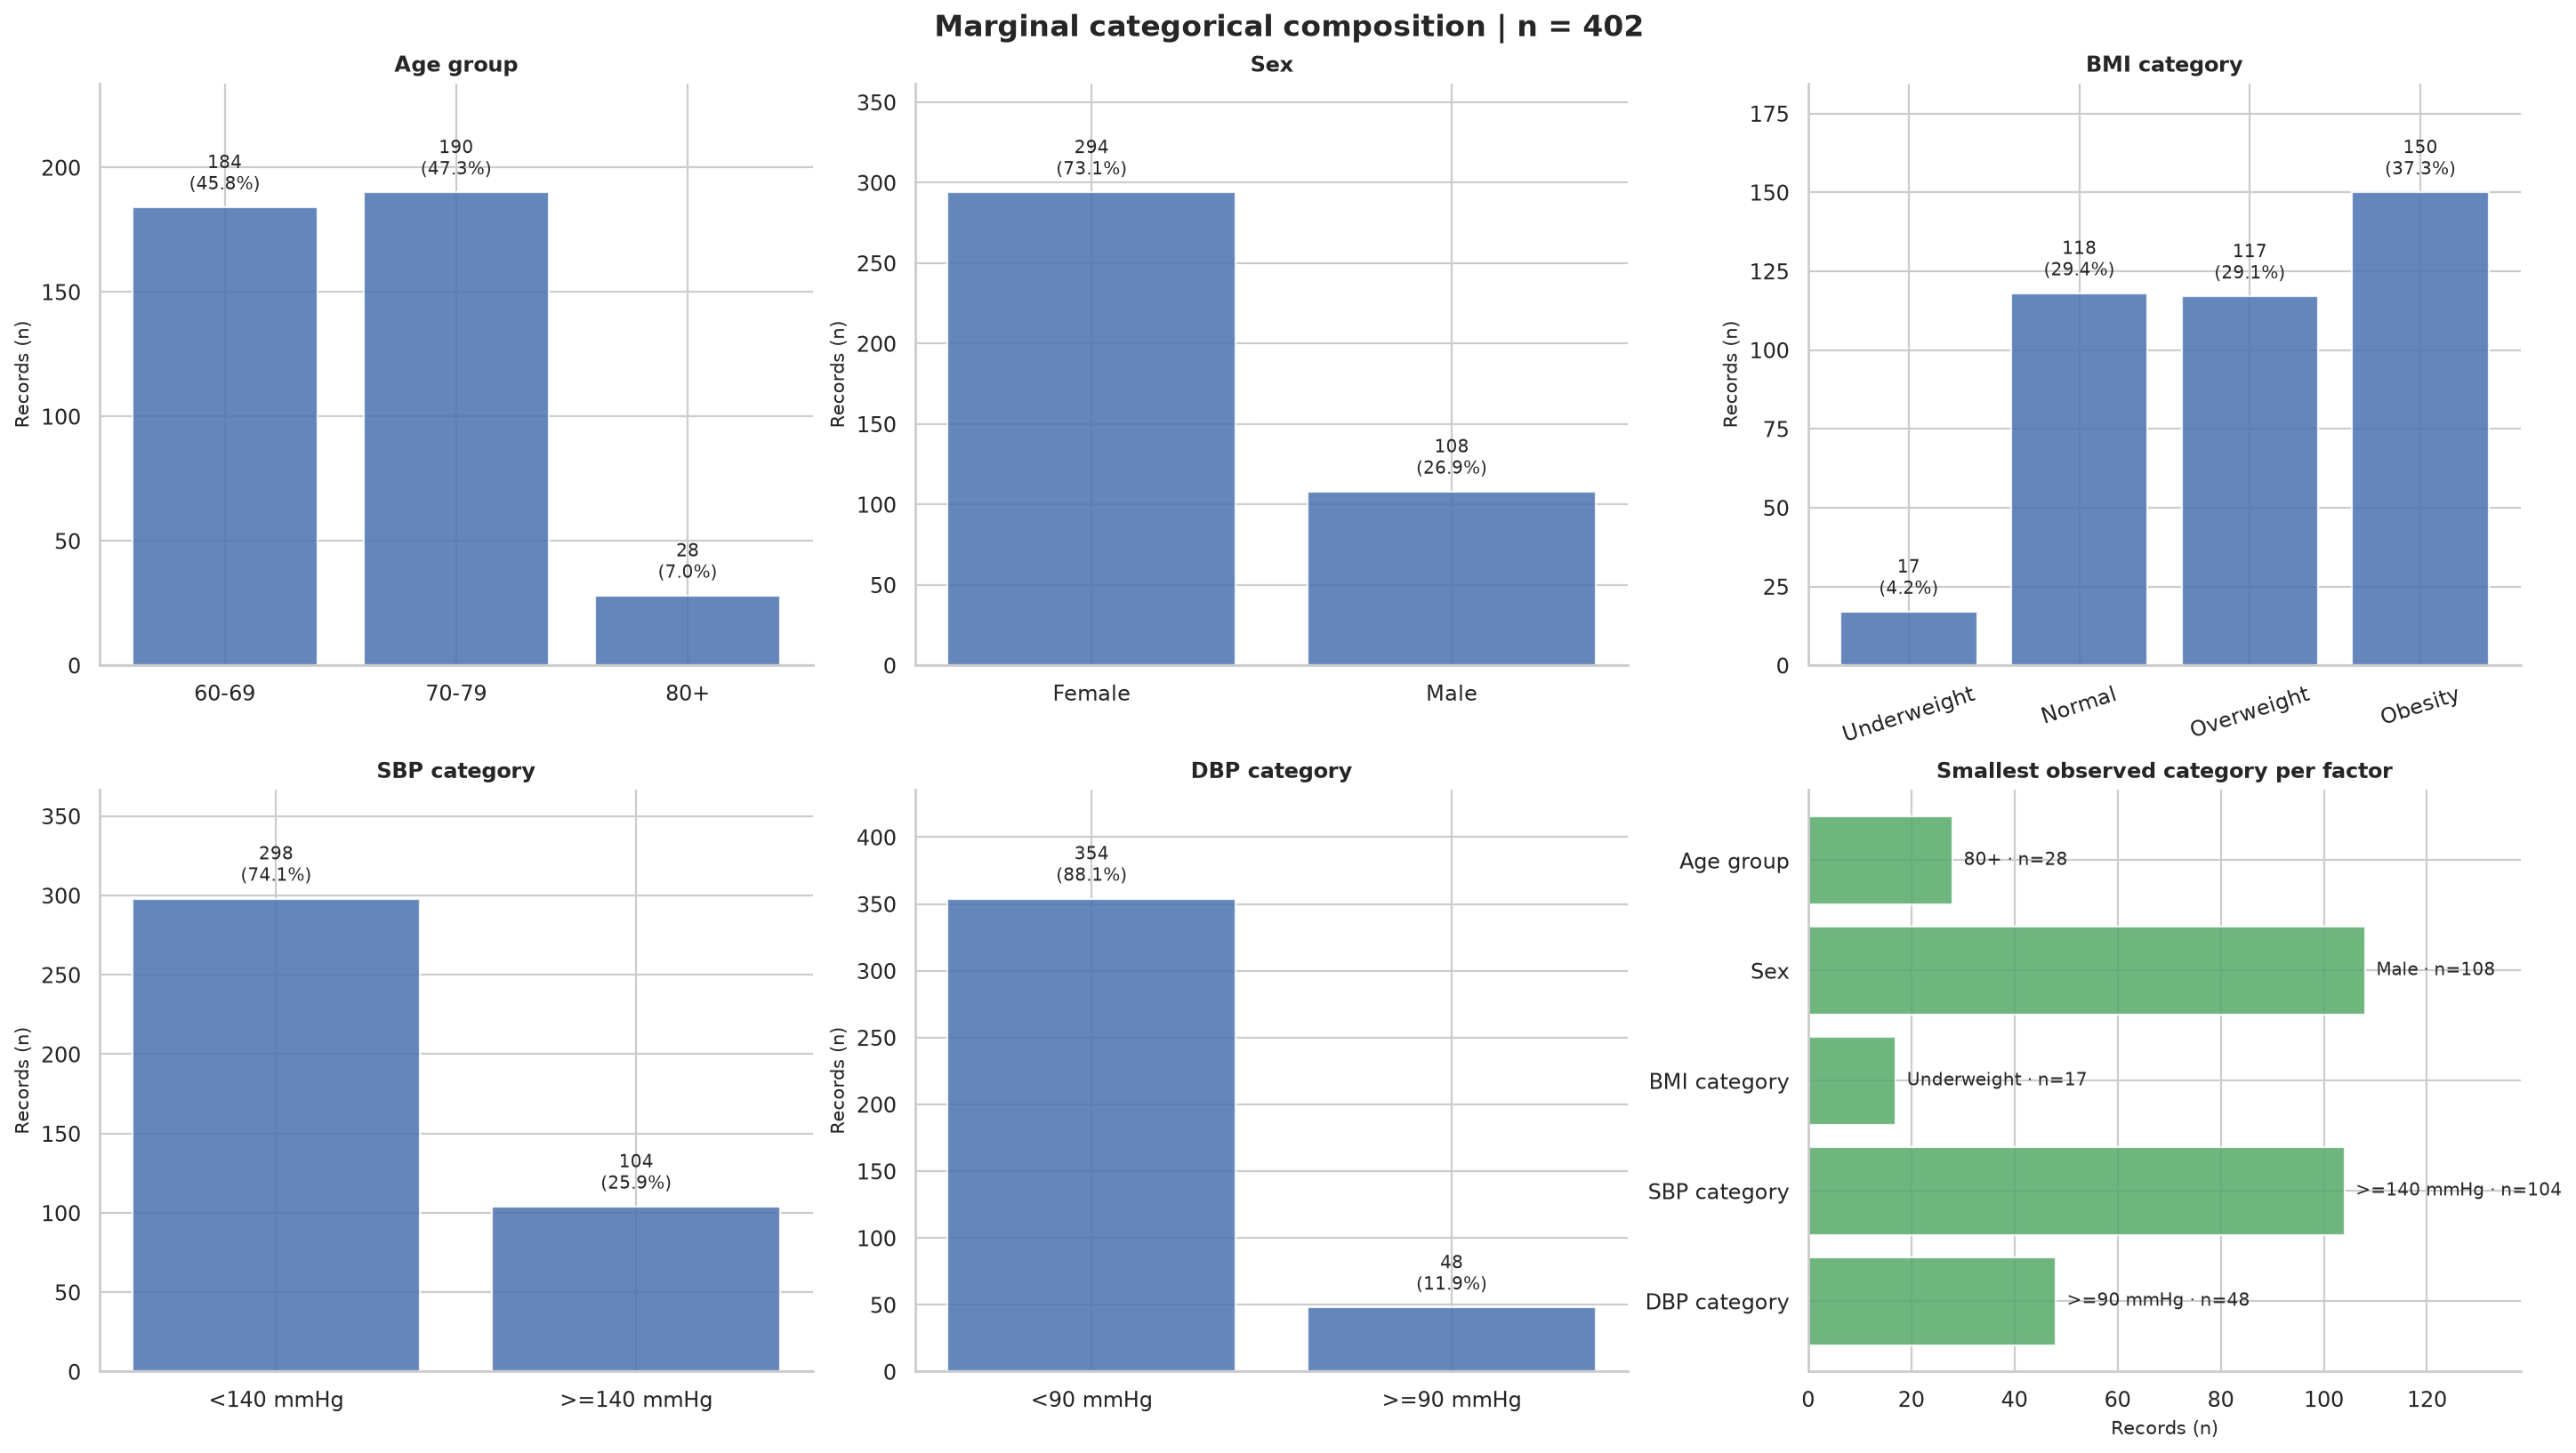

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18.0, 10.1), constrained_layout=True)
for ax, (factor, levels) in zip(axes.flat[:5], FACTOR_LEVELS.items()):
    subset = marginal[(marginal.factor == factor) & (marginal.category != '(missing)')]
    values = subset.set_index('category').reindex(levels)
    positions = np.arange(len(levels))
    bars = ax.bar(positions, values['n'].to_numpy(), color=sns.color_palette('deep')[0], alpha=0.86)
    ax.set_xticks(positions, labels=levels, rotation=18 if factor in ('bmi_category',) else 0)
    ax.set_title(FACTOR_LABELS[factor])
    ax.set_ylabel('Records (n)')
    ax.set_ylim(0, max(1, values['n'].max()) * 1.23)
    for bar, count, percentage in zip(bars, values['n'], values['pct_valid']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(1, values['n'].max())*.025,
                f'{int(count)}\n({percentage:.1f}%)', ha='center', va='bottom', fontsize=9)
    sns.despine(ax=ax)

min_ax = axes.flat[5]
smallest = []
for factor, levels in FACTOR_LEVELS.items():
    block = marginal[(marginal.factor == factor) & (marginal.category != '(missing)')]
    record = block.sort_values('n', kind='stable').iloc[0]
    smallest.append((factor, str(record['category']), int(record['n'])))
labels = [FACTOR_LABELS[factor] for factor, _, _ in smallest]
counts = [n for _, _, n in smallest]
min_ax.barh(labels, counts, color=sns.color_palette('deep')[2], alpha=0.85)
min_ax.set(title='Smallest observed category per factor', xlabel='Records (n)')
min_ax.invert_yaxis()
min_ax.set_xlim(0, max(counts) * 1.28)
for i, (_, level, n) in enumerate(smallest):
    min_ax.text(n + max(counts)*.02, i, f'{level} · n={n}', va='center', fontsize=9)
sns.despine(ax=min_ax)
fig.suptitle(f'Marginal categorical composition | n = {N_RECORDS}', fontsize=15, fontweight='semibold')
fig_path = save_figure(fig, '01_category_marginal_counts.png', 'marginal_counts',
                       'Five individual category counts and percentages, plus least-represented levels')
show_panel(fig_path)

## 4. All two-factor cross-tabulations

Compute **every one of the ten distinct pairs** formed by the five categorical factors. For each possible level combination, record:

- joint cell count `n`, including **zero-count cells**;
- share of all complete records for that pair (`joint_pct`);
- proportion **within the first/row factor** (`row_pct`);
- proportion **within the second/column factor** (`column_pct`);
- row/column denominators, pairwise missingness, and cell support.

These are *data availability tables*, not factorial models. The same record can appear in many different cross-tabulations. Pairwise cells must not be added across different factor pairs.

In [4]:
pairwise_rows = []
support_rows = []
PAIR_MATRICES = {}
for factor_a, factor_b in ALL_PAIRS:
    levels_a, levels_b = FACTOR_LEVELS[factor_a], FACTOR_LEVELS[factor_b]
    complete = source_df[[factor_a, factor_b]].dropna()
    n_complete = len(complete)
    cross = pd.crosstab(complete[factor_a], complete[factor_b])
    cross = cross.reindex(index=levels_a, columns=levels_b, fill_value=0).astype(int)
    PAIR_MATRICES[(factor_a, factor_b)] = cross
    row_totals = cross.sum(axis=1)
    col_totals = cross.sum(axis=0)
    for row_level in levels_a:
        for col_level in levels_b:
            count = int(cross.loc[row_level, col_level])
            pairwise_rows.append({
                'factor_a': factor_a, 'factor_b': factor_b,
                'category_a': row_level, 'category_b': col_level,
                'n': count,
                'joint_pct': 100 * count / n_complete if n_complete else np.nan,
                'row_pct': 100 * count / row_totals.loc[row_level] if row_totals.loc[row_level] else np.nan,
                'column_pct': 100 * count / col_totals.loc[col_level] if col_totals.loc[col_level] else np.nan,
                'row_n': int(row_totals.loc[row_level]),
                'column_n': int(col_totals.loc[col_level]),
                'n_pair_complete': n_complete,
                'n_pair_missing': N_RECORDS - n_complete,
                'is_empty': count == 0,
                'is_occupied_below_5': 0 < count < 5,
                'is_occupied_below_10': 0 < count < 10,
            })

    cells = cross.to_numpy().ravel()
    positive = cells[cells > 0]
    support_rows.append({
        'factor_a': factor_a, 'factor_b': factor_b,
        'comparison': f'{FACTOR_LABELS[factor_a]} × {FACTOR_LABELS[factor_b]}',
        'n_pair_complete': n_complete,
        'n_pair_missing': N_RECORDS - n_complete,
        'n_possible_cells': len(cells),
        'n_occupied_cells': int((cells > 0).sum()),
        'n_empty_cells': int((cells == 0).sum()),
        'n_occupied_cells_below_5': int(((cells > 0) & (cells < 5)).sum()),
        'n_occupied_cells_below_10': int(((cells > 0) & (cells < 10)).sum()),
        'min_occupied_n': int(positive.min()) if len(positive) else np.nan,
        'median_occupied_n': float(np.median(positive)) if len(positive) else np.nan,
        'max_occupied_n': int(positive.max()) if len(positive) else np.nan,
    })
    assert int(cells.sum()) == n_complete

pairwise = pd.DataFrame(pairwise_rows)
support = pd.DataFrame(support_rows)
assert len(support) == 10
assert len(pairwise) == sum(len(FACTOR_LEVELS[a]) * len(FACTOR_LEVELS[b]) for a,b in ALL_PAIRS)
for a,b in ALL_PAIRS:
    sub = pairwise[(pairwise.factor_a == a) & (pairwise.factor_b == b)]
    assert int(sub.n.sum()) == int(sub.n_pair_complete.iloc[0])

pairwise.to_csv(TABLES_DIR / 'categorical_pairwise_cell_counts.csv', index=False)
support.to_csv(TABLES_DIR / 'categorical_pairwise_support_summary.csv', index=False)
display(support[['comparison', 'n_pair_complete', 'n_possible_cells', 'n_occupied_cells',
                 'n_empty_cells', 'n_occupied_cells_below_5', 'min_occupied_n',
                 'max_occupied_n']])
print('Small and empty cells are OBSERVED SAMPLE COUNTS, not exclusion or estimability rules.')

,comparison,n_pair_complete,n_possible_cells,n_occupied_cells,n_empty_cells,n_occupied_cells_below_5,min_occupied_n,max_occupied_n
0,Age group × Sex,402,6,6,0,0,6,141
1,Age group × BMI category,402,12,12,0,2,1,80
2,Sex × BMI category,402,8,8,0,1,2,112
3,SBP category × DBP category,402,4,4,0,0,15,283
4,BMI category × SBP category,402,8,8,0,1,3,105
5,BMI category × DBP category,402,8,7,1,0,9,126
6,Age group × SBP category,402,6,6,0,0,7,143
7,Age group × DBP category,402,6,5,1,0,17,173
8,Sex × SBP category,402,4,4,0,0,31,221
9,Sex × DBP category,402,4,4,0,0,18,264


Small and empty cells are OBSERVED SAMPLE COUNTS, not exclusion or estimability rules.


## 5. Multipanel cross-tabulations by scientific domain

Each heatmap cell displays **the actual count and its row percentage** (the denominator is all available observations in the category shown on the vertical axis). Color encodes the count `n`, not a statistical effect.

Comparisons are arranged into three thematic sheets, rather than separate figures for each pair:

1. Age, sex, and BMI (3 pairs).
2. SBP, DBP, and BMI (3 pairs).
3. Demography by SBP or DBP (4 pairs).

The cross-tabulation of SBP with DBP is deliberately included **for composition inspection only**; it does not prescribe using both as independent model factors later.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


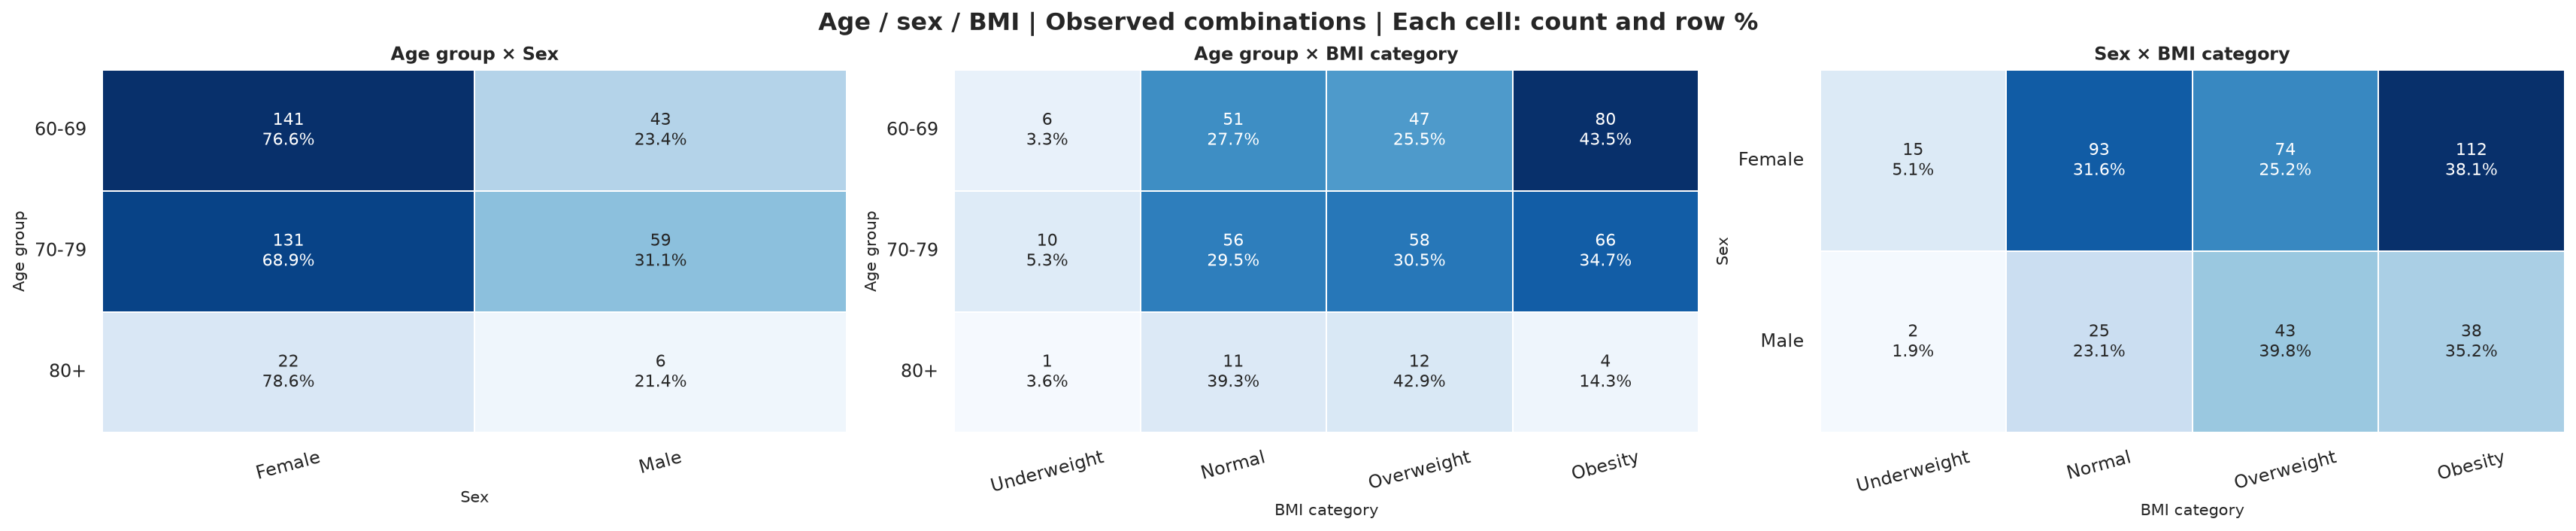

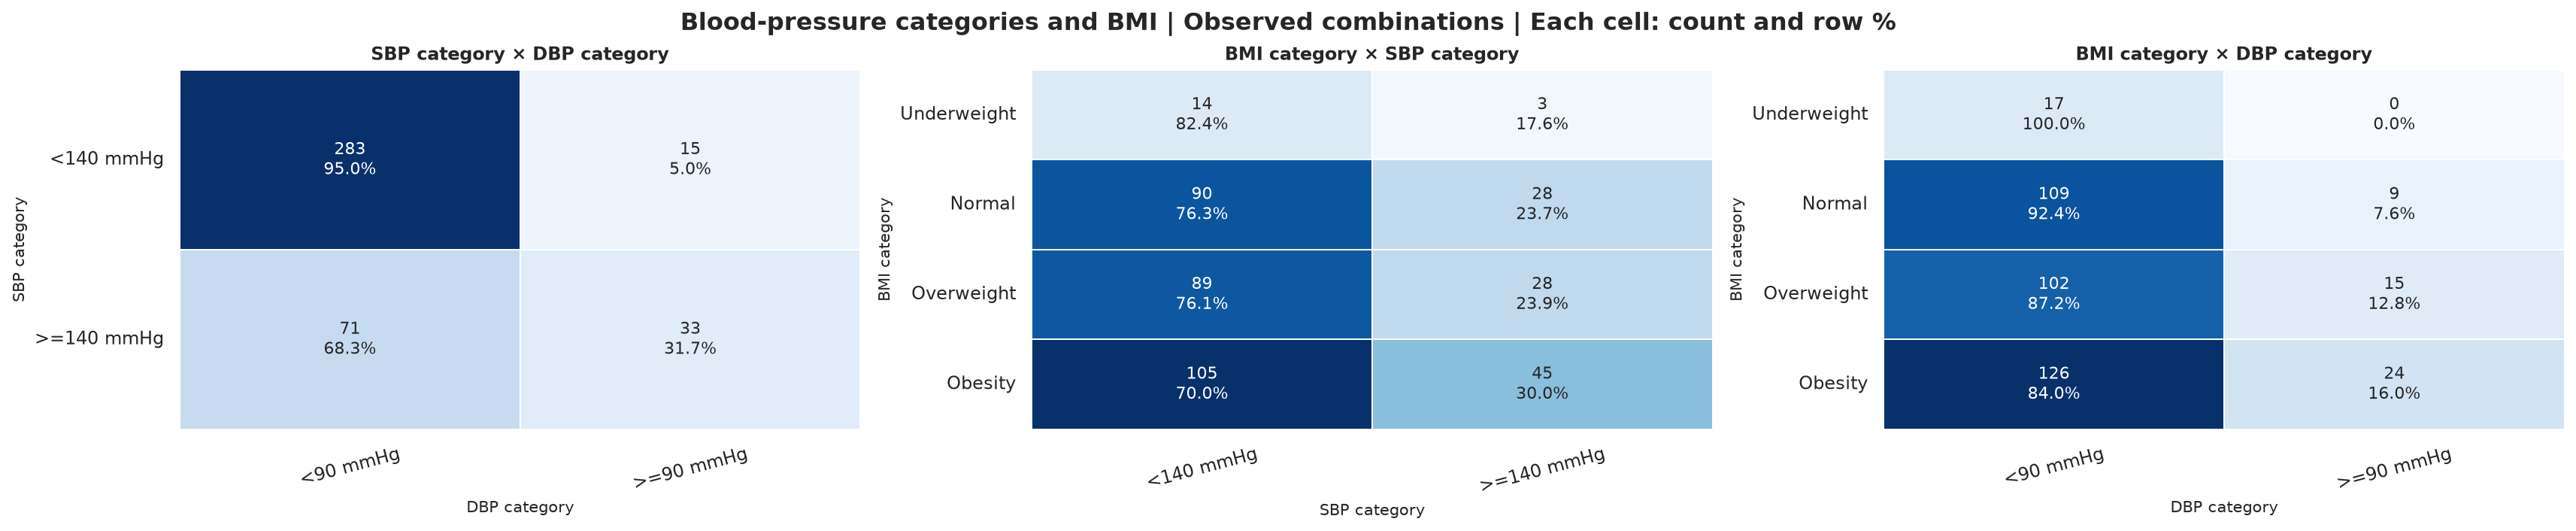

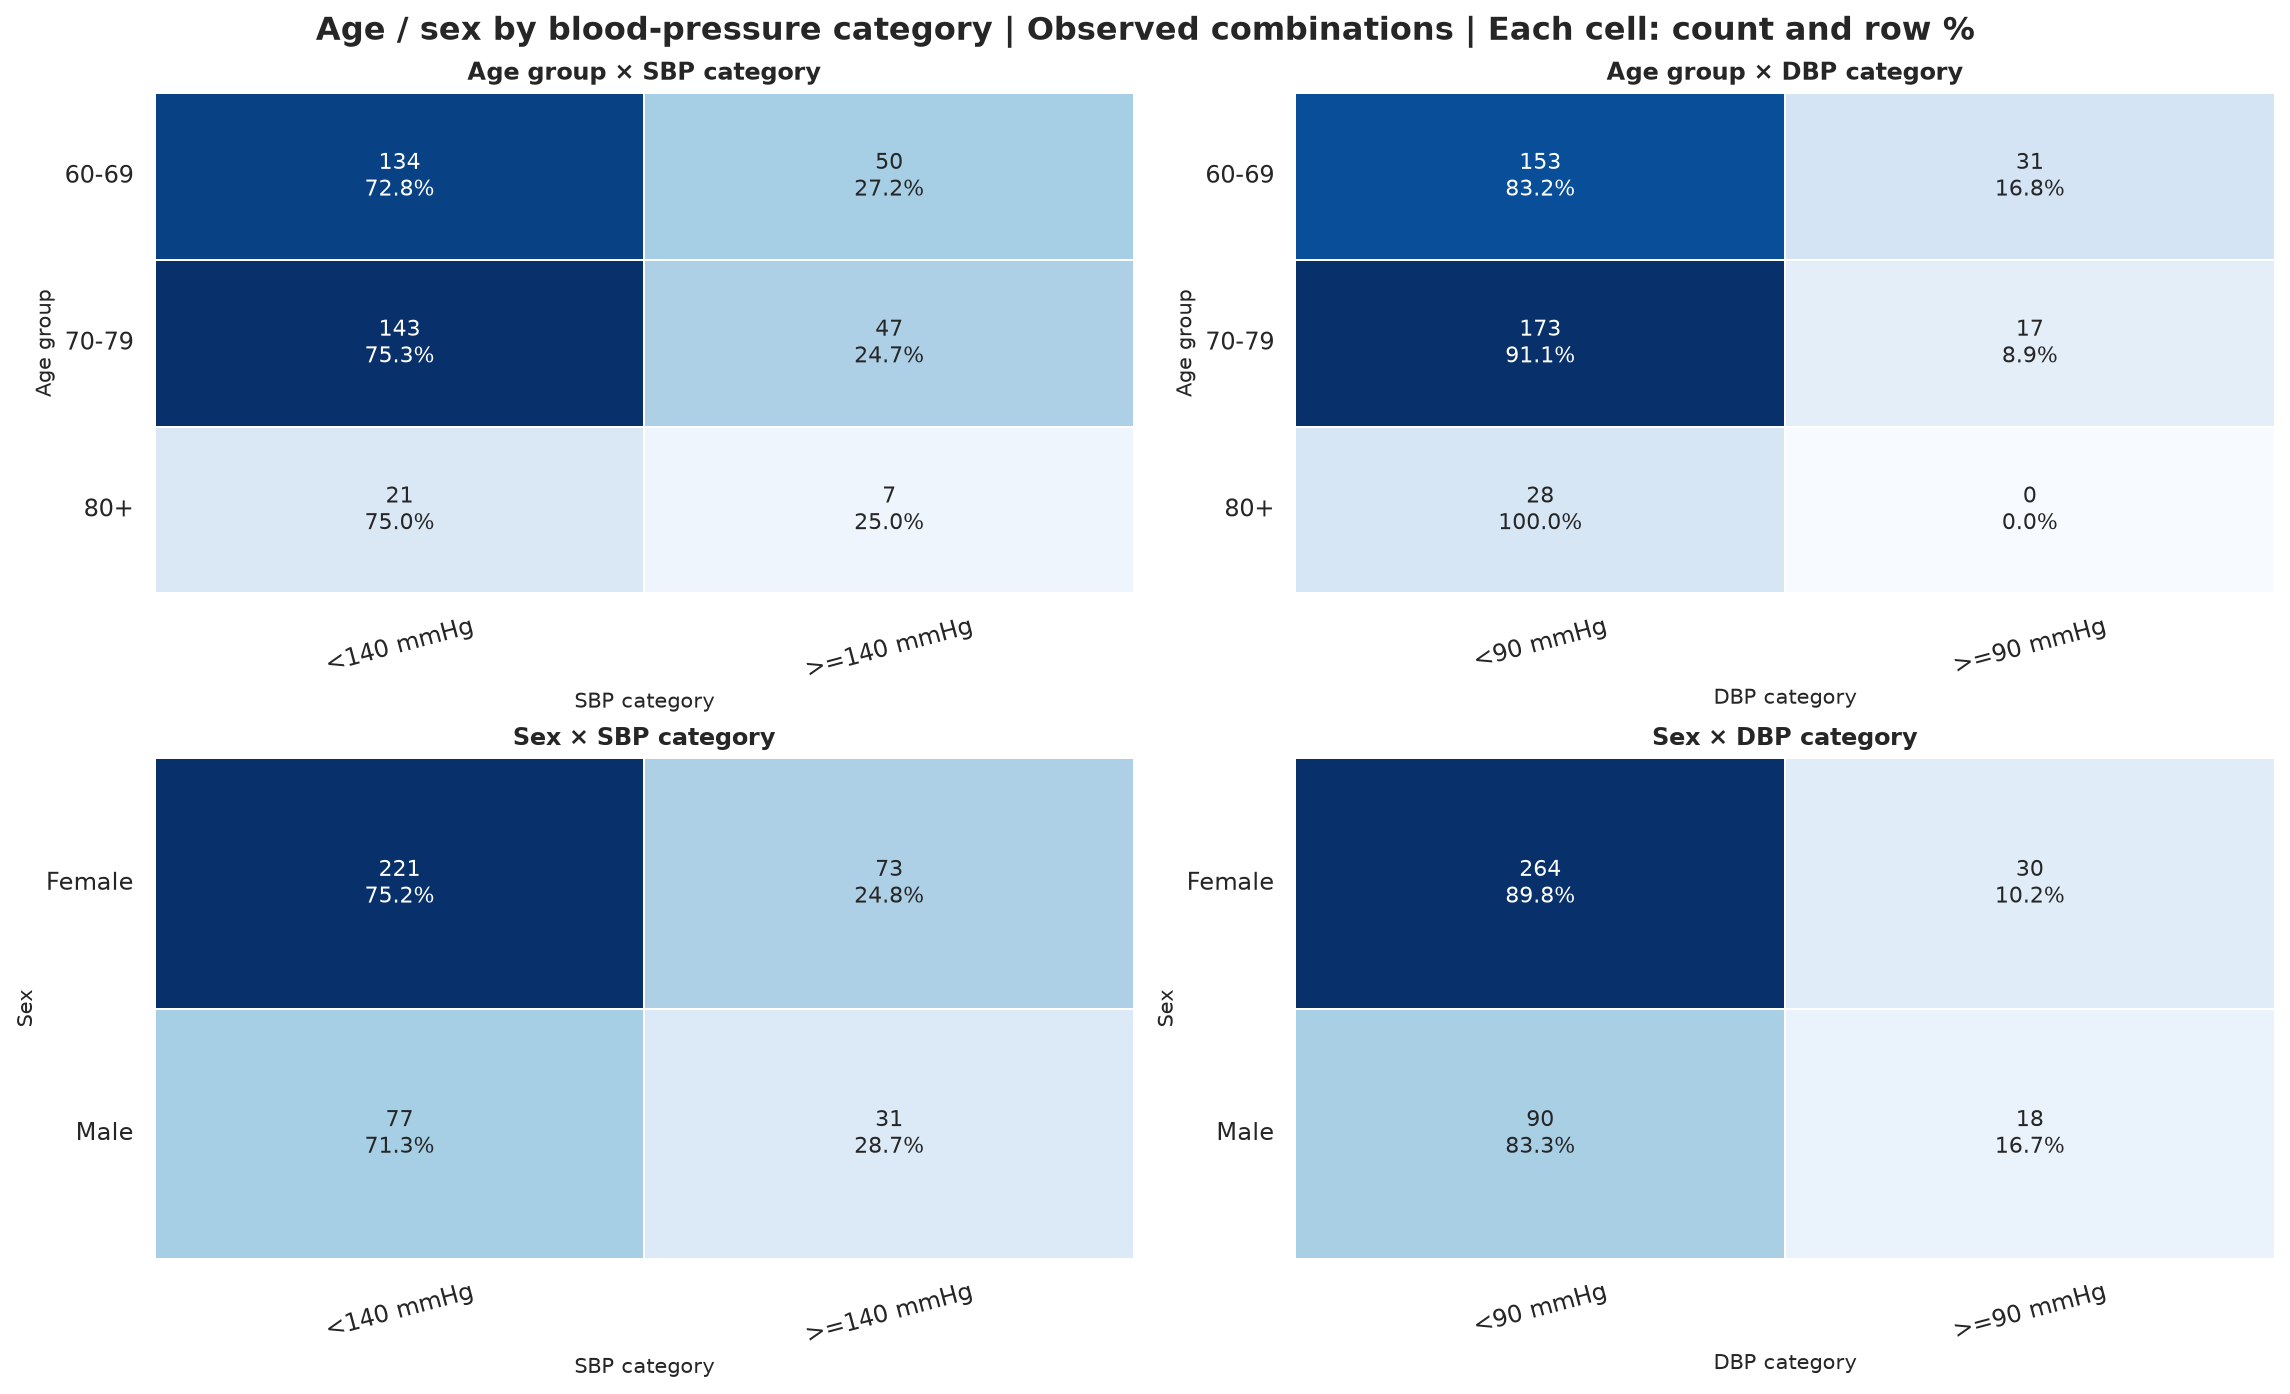

In [5]:
def draw_crosstab(ax, factor_a, factor_b):
    cross = PAIR_MATRICES[(factor_a, factor_b)]
    row_denoms = cross.sum(axis=1)
    labels = []
    for i, row_level in enumerate(cross.index):
        row_labels = []
        for j, col_level in enumerate(cross.columns):
            value = int(cross.iloc[i,j])
            denominator = int(row_denoms.loc[row_level])
            if denominator:
                row_labels.append(f'{value}\n{100*value/denominator:.1f}%')
            else:
                row_labels.append(f'{value}\n—')
        labels.append(row_labels)
    sns.heatmap(cross, ax=ax, annot=np.asarray(labels, dtype=object), fmt='',
                cmap='Blues', cbar=False, linewidths=.7, linecolor='white',
                annot_kws={'size': 10}, vmin=0)
    ax.set_title(f'{FACTOR_LABELS[factor_a]} × {FACTOR_LABELS[factor_b]}')
    ax.set_xlabel(FACTOR_LABELS[factor_b])
    ax.set_ylabel(FACTOR_LABELS[factor_a])
    ax.tick_params(axis='x', labelrotation=15)
    ax.tick_params(axis='y', labelrotation=0)


def domain_heatmap_panel(pairs, filename, heading, ncols):
    nrows = int(np.ceil(len(pairs) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(7.1*ncols, 4.3*nrows), constrained_layout=True,
                             squeeze=False)
    for ax, (a, b) in zip(axes.flat, pairs):
        draw_crosstab(ax, a, b)
    for ax in list(axes.flat)[len(pairs):]:
        ax.axis('off')
    fig.suptitle(heading + ' | Each cell: count and row %', fontsize=14.5, fontweight='semibold')
    return save_figure(fig, filename, 'pairwise_crosstabs',
                       f'{len(pairs)} category cross-tabulations (n and row percentage; no inference)')

p = domain_heatmap_panel(
    PAIR_SECTIONS['demographic_anthropometric'],
    '02_demography_anthropometry_crosstabs.png',
    'Age / sex / BMI | Observed combinations', ncols=3)
show_panel(p)

p = domain_heatmap_panel(
    PAIR_SECTIONS['blood_pressure_and_bmi'],
    '03_blood_pressure_bmi_crosstabs.png',
    'Blood-pressure categories and BMI | Observed combinations', ncols=3)
show_panel(p)

p = domain_heatmap_panel(
    PAIR_SECTIONS['demographics_and_blood_pressure'],
    '04_demographic_bp_crosstabs.png',
    'Age / sex by blood-pressure category | Observed combinations', ncols=2)
show_panel(p)

## 6. Multipanel summary of pairwise cell support

This overview provides a quick check of **which two-factor subdivisions are well represented and which contain few/no records**. The cutoffs `1–4` and `≥5` are **descriptive bin labels only** and are never used to reject cells, individuals, or later models.

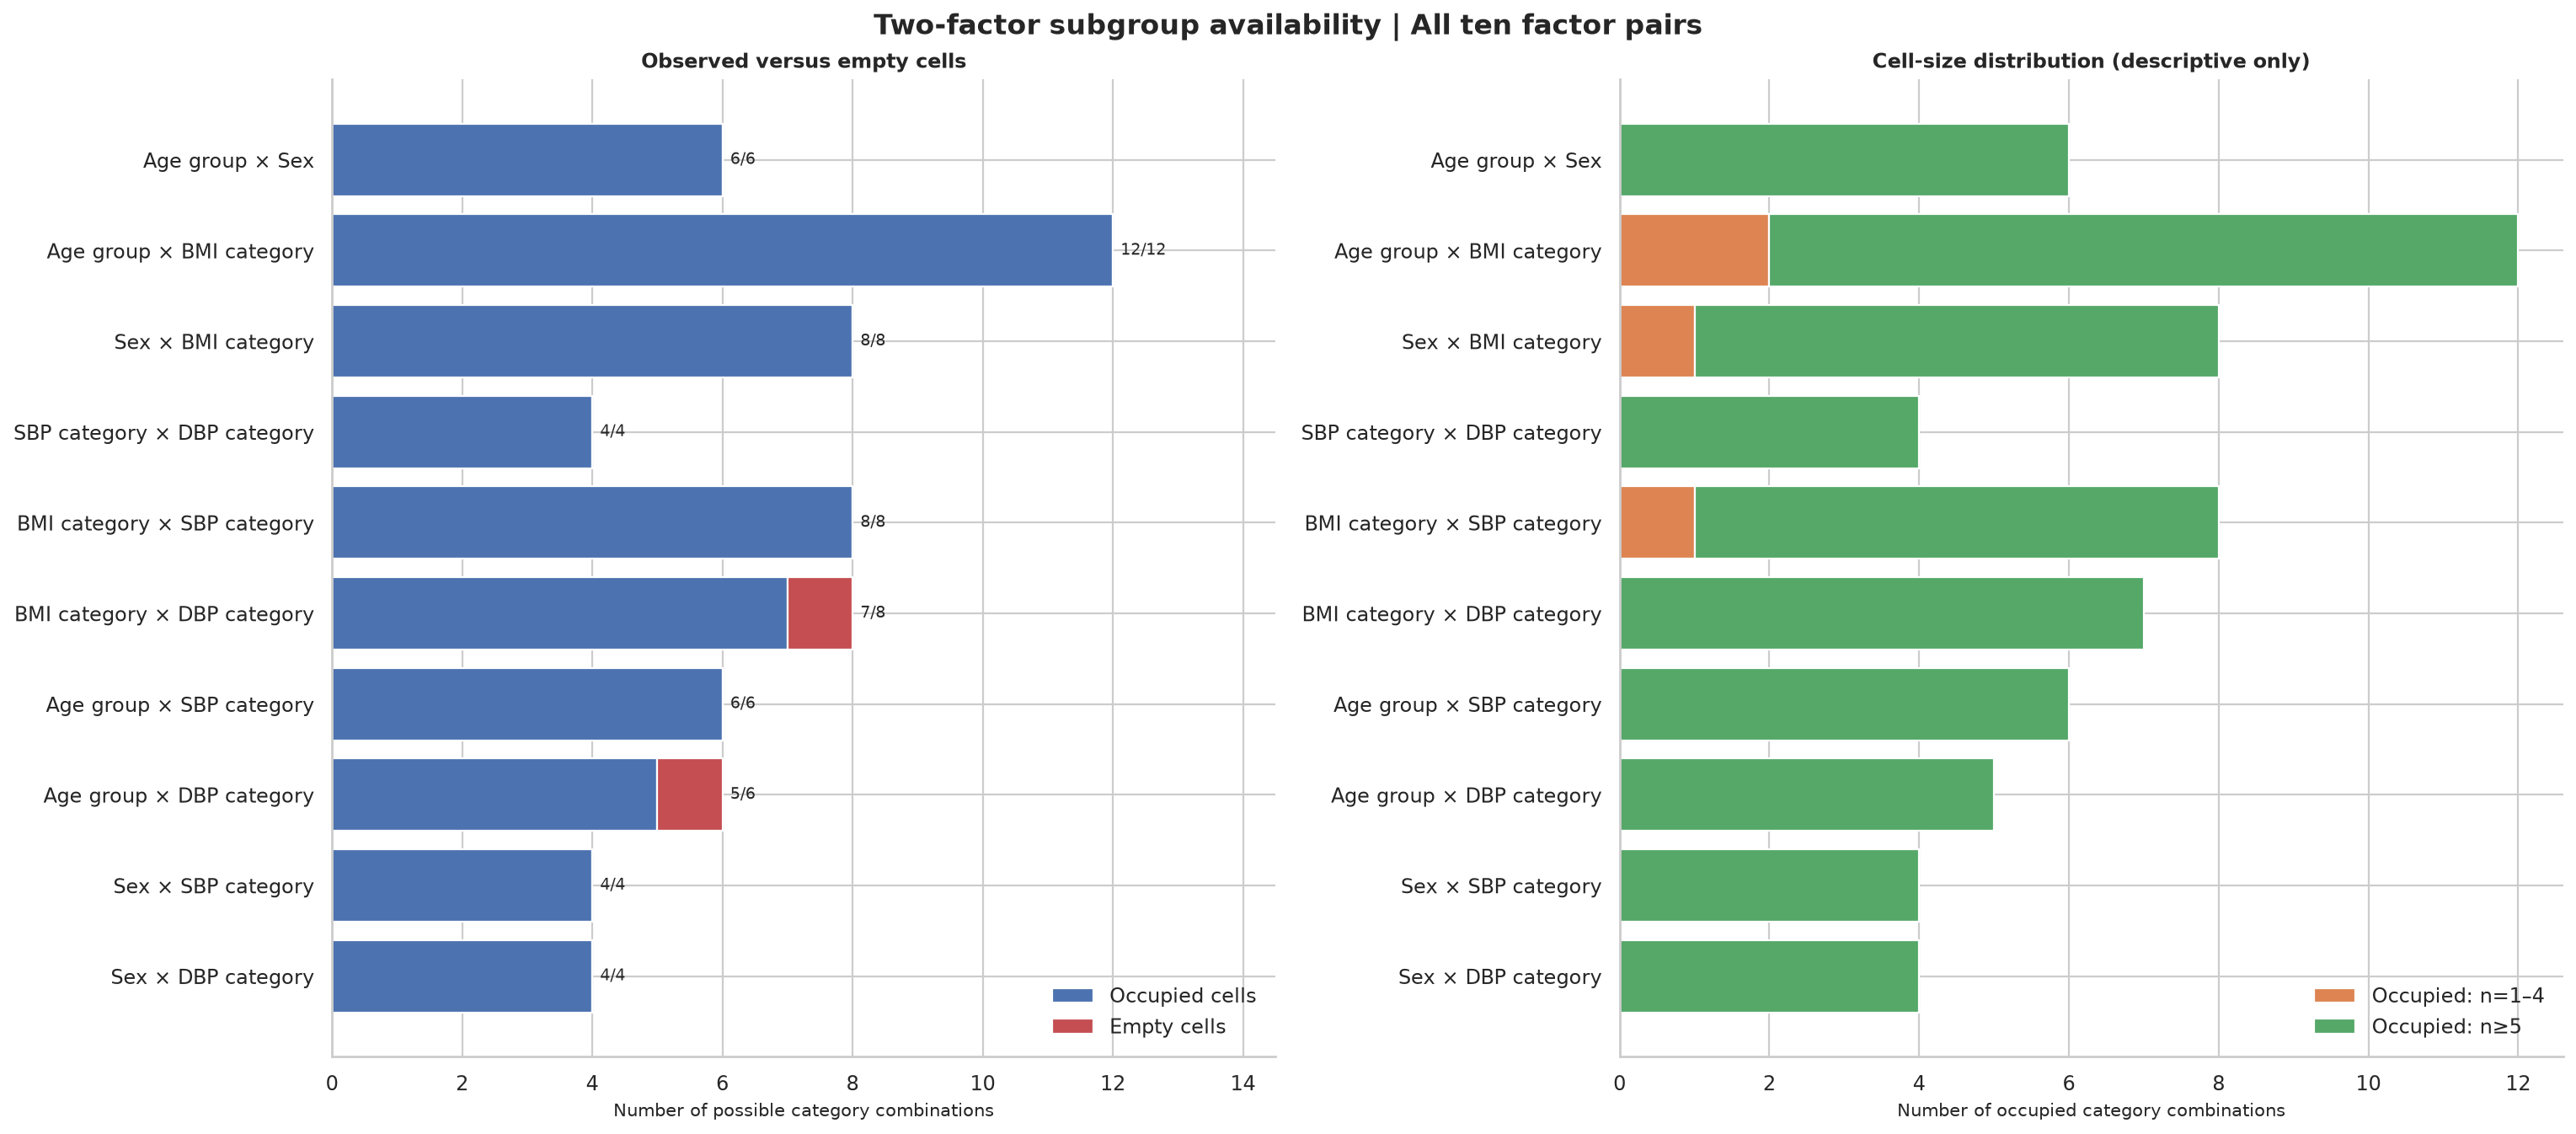

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(19, 8.3), constrained_layout=True)
show = support.iloc[::-1].copy()
pos = np.arange(len(show))
ax = axes[0]
ax.barh(pos, show['n_occupied_cells'], label='Occupied cells', color=sns.color_palette('deep')[0])
ax.barh(pos, show['n_empty_cells'], left=show['n_occupied_cells'],
        label='Empty cells', color=sns.color_palette('deep')[3])
ax.set_yticks(pos, labels=show['comparison'])
ax.set_xlabel('Number of possible category combinations')
ax.set_title('Observed versus empty cells')
ax.legend(frameon=False, loc='lower right')
for i, row in enumerate(show.itertuples()):
    ax.text(row.n_possible_cells + 0.12, i, f'{row.n_occupied_cells}/{row.n_possible_cells}',
            va='center', fontsize=8.5)
ax.set_xlim(0, show['n_possible_cells'].max() + 2.5)
sns.despine(ax=ax)

ax = axes[1]
ax.barh(pos, show['n_occupied_cells_below_5'],
        label='Occupied: n=1–4', color=sns.color_palette('deep')[1])
ax.barh(pos, show['n_occupied_cells']-show['n_occupied_cells_below_5'],
        left=show['n_occupied_cells_below_5'],
        label='Occupied: n≥5', color=sns.color_palette('deep')[2])
ax.set_yticks(pos, labels=show['comparison'])
ax.set_xlabel('Number of occupied category combinations')
ax.set_title('Cell-size distribution (descriptive only)')
ax.legend(frameon=False, loc='lower right')
sns.despine(ax=ax)

fig.suptitle('Two-factor subgroup availability | All ten factor pairs', fontsize=15, fontweight='semibold')
p = save_figure(fig, '05_pairwise_cell_support.png', 'pairwise_support',
                'Occupied vs empty cells and descriptive sizes across the ten factor pairs')
show_panel(p)

## 7. Automated README, results summary, and final output checks

The notebook generates two Markdown files automatically:

- `README_05_category_counts.md` — purpose, definitions, denominators, analytical scope, file inventory, and reproducibility metadata.
- `05_category_counts_results.md` — **actual** marginal frequencies, pairwise cell support, selected examples of sparse cells, and the figure index.

Both Markdown files and all CSV/PNG outputs are **results of executing this notebook**, not deliverables embedded in the ZIP. No substantive interpretation of HRV relationships is made here.

In [7]:
figure_manifest = pd.DataFrame(figure_records)
assert len(figure_manifest) == 5, f'Expected 5 multipanel figures, generated {len(figure_manifest)}.'
assert figure_manifest['figure'].is_unique
figure_manifest.to_csv(TABLES_DIR / 'figure_manifest.csv', index=False)


def md_value(value, decimals=1):
    if pd.isna(value):
        return 'NA'
    if isinstance(value, (int, np.integer)):
        return str(value)
    if isinstance(value, (float, np.floating)):
        return f'{float(value):.{decimals}f}'
    return str(value).replace('|', r'\|').replace('\n',' ')


def markdown_table(frame, columns, decimals=1):
    header = '| ' + ' | '.join(columns) + ' |'
    line = '| ' + ' | '.join(['---'] * len(columns)) + ' |'
    items = [header, line]
    for _, row in frame.loc[:, columns].iterrows():
        items.append('| ' + ' | '.join(md_value(row[col], decimals) for col in columns) + ' |')
    return '\n'.join(items)

marginal_display = marginal[marginal['category'] != '(missing)'][
    ['factor_label', 'category', 'n', 'pct_valid']
].copy()
small_pairs = pairwise[pairwise['is_occupied_below_5']].copy()
small_pairs = small_pairs.sort_values(['n', 'factor_a', 'factor_b', 'category_a', 'category_b'])
small_pairs['comparison'] = (small_pairs['factor_a'].map(FACTOR_LABELS) + ' × ' +
                             small_pairs['factor_b'].map(FACTOR_LABELS))
small_display = small_pairs[['comparison','category_a','category_b','n','row_pct']].head(25)
empty_pairs = pairwise[pairwise['is_empty']].copy()
empty_pairs['comparison'] = (empty_pairs['factor_a'].map(FACTOR_LABELS) + ' × ' +
                             empty_pairs['factor_b'].map(FACTOR_LABELS))
empty_display = empty_pairs[['comparison','category_a','category_b','n']].head(25)

readme = f'''# Data inspection — 05.03 Categorical counts

## Objective and scientific boundary

This notebook inventories category frequencies and two-factor combinations in the **already selected analytical sample**. It does **not** analyze HRV values, compare HRV between groups, run statistical tests, fit models, assess interactions, build three-/four-factor strata, or modify records.

## Position within the inspection stage

1. `05_01_hrv_inspection.ipynb` — seven HRV and cardiac measures.
2. `05_02_non_hrv_inspection.ipynb` — continuous age, anthropometry and blood-pressure variables.
3. `05_03_category_counts.ipynb` — categorical counts and pairwise cross-tabulations (**this notebook**).

## Data, traceability, and reproducibility

- Input: `outputs/dataset_final.csv` from preprocessing `01 → 01b → 02 → 03 → 04`.
- Number of records analyzed: **{N_RECORDS}** (documented release: {EXPECTED_N}).
- Identifier: `{SOURCE_COLUMN}`; duplicates and missing IDs are rejected.
- Source SHA-256: `{INPUT_SHA256}`.
- BMI classification reference: {str(source_df['bmi_reference'].iloc[0])} (all rows verified).
- Original source columns are **never changed, recoded, or written back**.
- Running from within the project tree discovers `outputs/dataset_final.csv`; alternatively set `INPUT_FILE_OVERRIDE` in the configuration cell.

## Recorded categories and order

| Factor | Ordered levels |
| --- | --- |
''' + '\n'.join(
    f'| `{factor}` | {", ".join(levels)} |' for factor, levels in FACTOR_LEVELS.items()
) + f'''

Sex code mapping in the source is **1 = Female**, **2 = Male**. The categories are checked against the numeric source fields from preprocessing, with older-adult BMI thresholds **23, 28, 32**, and independent systolic and diastolic thresholds **140 and 90 mmHg**. The `bmi_reference` field is metadata, not a sixth modeled factor.

## Counting conventions

- Marginal `n`: records in a category; `pct_valid`: percentage among nonmissing labels for that factor; `pct_of_all_records`: percentage of all {N_RECORDS} records. A separate `(missing)` row is included for every factor.
- Pairwise `n`: records with both listed category labels. Zero cells are explicitly included using the full Cartesian product of **documented levels**, not omitted by default cross-tabulation behavior.
- Pairwise `joint_pct`: percentage of records with both factors observed; `row_pct`: within the first category (vertical heatmap axis); `column_pct`: within the second category.
- Cross-tabulation rows and columns are the two levels being compared. Each 2-way cross-tabulation sums to its *own* complete-pair denominator. Counts from different pairs are not independent and cannot be summed.
- A cell of n=0 or n=1–4 is a **descriptive statement about sample support**, not a diagnosis of bad data, a mandatory exclusion, or a test of statistical estimability.
- No chi-square test, p-value, multivariable model, arbitrary group merging, imputation, or subgroup filtering occurs.
- Only **two-factor** combinations are examined. Three/four/five-factor intersections are intentionally outside this notebook.

## Files generated in this run

Root: `eda_results/data_inspection/05_03_category_counts/`

- `tables/categorical_marginal_counts.csv` — all categories and a separate missing row per factor.
- `tables/bmi_reference_metadata_counts.csv` — classification-reference metadata only.
- `tables/categorical_source_consistency_checks.csv` — original-label validation.
- `tables/categorical_pairwise_cell_counts.csv` — all 10 pairs, including empty cells, with absolute and conditional percentages.
- `tables/categorical_pairwise_support_summary.csv` — cell support and small/empty cell counts.
- `tables/figure_manifest.csv` — exact generated figure filenames.
- `figures/multipanels/` — {len(figure_manifest)} consolidated figures.
- `README_05_category_counts.md` — this methods document.
- `05_category_counts_results.md` — generated counts and evidence tables.

On reruns, only previously generated PNGs **listed in this notebook's own manifest** are replaced inside the stage multipanel directory. Unrelated files are preserved.

## Environment

- Python: {platform.python_version()}
- pandas: {pd.__version__}
- NumPy: {np.__version__}
- matplotlib: {matplotlib.__version__}
- seaborn: {sns.__version__}
'''

results_md = f'''# 05.03 Category counts — Descriptive results

**Input:** `{INPUT_FILE.name}` · **Analyzed records:** {N_RECORDS} · **Factors:** {len(FACTOR_LEVELS)} · **Two-factor comparisons:** {len(ALL_PAIRS)}

## 1. Individual category counts

**Percentages** are calculated among nonmissing category labels for each factor. Every reported `n` refers to an actual source record, not a unique verified participant ID.

{markdown_table(marginal_display, list(marginal_display.columns), 1)}

All factors have the following missing-category counts:

{markdown_table(marginal[marginal.category == '(missing)'][['factor_label','n','pct_of_all_records']], ['factor_label','n','pct_of_all_records'], 1)}

BMI classification-reference metadata:

{markdown_table(reference_counts, list(reference_counts.columns), 1)}

## 2. Two-factor cell availability (10 pairs)

{markdown_table(support[['comparison','n_pair_complete','n_possible_cells','n_occupied_cells','n_empty_cells','n_occupied_cells_below_5','min_occupied_n','median_occupied_n','max_occupied_n']],
 ['comparison','n_pair_complete','n_possible_cells','n_occupied_cells','n_empty_cells','n_occupied_cells_below_5','min_occupied_n','median_occupied_n','max_occupied_n'], 1)}

The complete cell-level table, including **n=0** combinations, `joint_pct`, `row_pct` and `column_pct`, is stored in `tables/categorical_pairwise_cell_counts.csv`.

## 3. Examples of occupied small cells (n = 1–4)

The table below lists up to 25 small cells, in increasing order of n. A small cell is **not** an exclusion criterion or evidence of non-estimability.

{markdown_table(small_display, list(small_display.columns), 1) if len(small_display) else 'None observed.'}

## 4. Examples of empty cells

{markdown_table(empty_display, list(empty_display.columns), 1) if len(empty_display) else 'None observed.'}

## 5. Figure index

{markdown_table(figure_manifest[['figure','description']], ['figure','description'])}

## 6. Interpretation boundaries

- All **{N_RECORDS}** records are retained unchanged in every tabulation.
- Results summarize **sample composition and subgroup availability**, not HRV measurements or group differences.
- The 10 pairs were counted explicitly, but no 3+ factor combinations were constructed.
- The sample contains multiple measures or categories that share physiological or mathematical information. The tables are descriptive only and do not prescribe later models.
- Figures and tables can inform later *unifactorial* HRV questions and identify logical two-factor profiles worth considering, without evaluating them here.
'''

(OUTPUT_DIR / 'README_05_category_counts.md').write_text(readme, encoding='utf-8')
(OUTPUT_DIR / '05_category_counts_results.md').write_text(results_md, encoding='utf-8')

assert int(marginal[marginal.category == '(missing)'].n.sum()) == 0, (
    'The current 402-record release was expected to have complete category fields; '
    'this assertion documents the release but does not remove any record.'
)
assert (validation['n_mismatch'] == 0).all()
assert source_df[SOURCE_COLUMN].is_unique and len(source_df) == N_RECORDS
print(f'Completed: n={N_RECORDS}; 5 factors; {len(ALL_PAIRS)} pairwise crosstabs; {len(figure_manifest)} multipanels.')
print('README:', OUTPUT_DIR / 'README_05_category_counts.md')
print('Results:', OUTPUT_DIR / '05_category_counts_results.md')
print('No data changes, HRV comparisons, statistical tests, models, or exclusions.')

Completed: n=402; 5 factors; 10 pairwise crosstabs; 5 multipanels.
README: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_03_category_counts/README_05_category_counts.md
Results: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_03_category_counts/05_category_counts_results.md
No data changes, HRV comparisons, statistical tests, models, or exclusions.
